# IMC Prosperity 4 — Ashflow Alpha Manual Round Optimizer

Use this notebook to translate your news view into portfolio weights while accounting for the quadratic fee.

**Main assumption:** if you allocate `x%` of the total budget to one product, the fee is

\[
\text{fee}_i = \left(\frac{x_i}{100}\right)^2 \times \text{budget}.
\]

So with signed weight \(w_i = x_i/100\), expected net PnL contribution is roughly

\[
\text{budget}\times(w_i \mu_i - |w_i|^2).
\]

This means the no-risk optimal allocation for a product is:

\[
|w_i|^* = \frac{|\mu_i|}{2}.
\]

Example: if you think a product will move +20%, the raw optimal long size is about 10% of budget, not 100%.


## News interpretation table

Edit the product names to match the exact names in the manual submission UI.

The `expected_return_pct` column is **your signed estimate** of the one-day return after reading the news.  
The `std_pct` column is your uncertainty estimate.  
The `confidence` column shrinks your estimate toward zero if the article is noisy / promotional / already priced-in.  
The `crowd_return_pct` column is an extra signed adjustment for how you think other teams' submissions will move the return inside its allowed range.

Positive expected return means **long**. Negative expected return means **short**.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BUDGET = 1_000_000

# Risk aversion:
# 0 = only fee-aware expected PnL.
# Larger values penalise uncertain products more.
RISK_AVERSION = 3.0

# Robustness:
# subtract ROBUST_Z * std from the signal magnitude before sizing.
# Try 0.0, 0.25, 0.5, 1.0 in the sensitivity section.
ROBUST_Z = 0.25

# Max absolute allocation to one product, as a fraction of the total budget.
DEFAULT_MAX_ABS_WEIGHT = 0.5

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


In [ ]:
signals = pd.DataFrame([
    {
        "product": "SULFUR_REACTOR",
        "direction": "LONG",
        "news_view": "Index inclusion: forced/index-tracker demand. Cleanest bullish catalyst.",
        "expected_return_pct": 30,
        "std_pct": 8,
    },
    {
        "product": "THERMALITE_SMART_HOME_DEVICES",
        "direction": "LONG",
        "news_view": "Quarterly forecast shows large usage/device growth. Strong fundamental demand.",
        "expected_return_pct": 10,
        "std_pct": 6,
    },
    {
        "product": "LAVA_FOUNTAIN_PEN",
        "direction": "LONG",
        "news_view": "Limited-edition drop sold out; strong demand, but maybe one-off.",
        "expected_return_pct": 8,
        "std_pct": 6,
    },
    {
        "product": "SCORIA_PASTE",
        "direction": "LONG",
        "news_view": "Influencer/market-medium says stockpile it. Bullish but less reliable.",
        "expected_return_pct": 2,
        "std_pct": 8,
    },
    {
        "product": "VOLCANIC_INCENSE",
        "direction": "LONG",
        "news_view": "Already rallying after public buy call. Momentum/crowding, but pump-like risk.",
        "expected_return_pct": 7,
        "std_pct": 8,

    },
    {
        "product": "LAVA_CAKES",
        "direction": "SHORT",
        "news_view": "Actual lava traces, health review, sales halted. Very clean bearish catalyst.",
        "expected_return_pct": -60,
        "std_pct": 10,
    },
    {
        "product": "OBSIDIAN_CUTLERY",
        "direction": "SHORT",
        "news_view": "Manufacturing halted after safety/assembly-line failure. Bearish.",
        "expected_return_pct": -30,
        "std_pct": 7,
    },
    {
        "product": "PYROFLEX_CELL",
        "direction": "SHORT",
        "news_view": "Tax cut abruptly ends; purchases/upgrades likely slow. Bearish.",
        "expected_return_pct": -20,
        "std_pct": 8,
    },
    {
        "product": "ASHES_OF_THE_PHOENIX",
        "direction": "SHORT",
        "news_view": "Resurfaced sourcing video causes public concern. Bearish/reputation risk.",
        "expected_return_pct": -5,
        "std_pct": 10,
    },
])

,product,direction,news_view,expected_return_pct,std_pct,confidence,crowd_return_pct,max_abs_weight_pct
0,SULFUR_REACTOR,LONG,Index inclusion: forced/index-tracker demand. Cleanest bullish catalyst.,20,8,0.9000,4,18
1,THERMALITE_SMART_HOME_DEVICES,LONG,Quarterly forecast shows large usage/device growth. Strong fundamental demand.,16,10,0.7500,2,15
2,LAVA_FOUNTAIN_PEN,LONG,"Limited-edition drop sold out; strong demand, but maybe one-off.",12,10,0.6000,2,12
3,MAGMA_INK,LONG,"Featured in sold-out fountain pen. Positive, but secondary exposure.",10,10,0.5500,1,10
4,SCORIA_PASTE,LONG,Influencer/market-medium says stockpile it. Bullish but less reliable.,8,14,0.4500,2,8
5,VOLCANIC_INCENSE,LONG,"Already rallying after public buy call. Momentum/crowding, but pump-like risk.",7,18,0.3500,2,6
6,LAVA_CAKES,SHORT,"Actual lava traces, health review, sales halted. Very clean bearish catalyst.",-20,10,0.9000,-3,18
7,OBSIDIAN_CUTLERY,SHORT,Manufacturing halted after safety/assembly-line failure. Bearish.,-16,11,0.8000,-2,15
8,PYROFLEX_CELL,SHORT,Tax cut abruptly ends; purchases/upgrades likely slow. Bearish.,-14,10,0.7500,-2,14
9,ASHES_OF_THE_PHOENIX,SHORT,Resurfaced sourcing video causes public concern. Bearish/reputation risk.,-15,13,0.7500,-2,14


## Optimizer

In [3]:
def prepare_signals(df, robust_z=ROBUST_Z):
    out = df.copy()
    out["mu_raw"] = out["expected_return_pct"] / 100
    out["sigma"] = out["std_pct"] / 100
    out["crowd_mu"] = out["crowd_return_pct"] / 100

    # Shrink by confidence and add expected crowd/submission effect
    out["mu_view"] = out["confidence"] * out["mu_raw"] + out["crowd_mu"]

    # Robust signal: reduce absolute signal by z * sigma.
    # If the uncertainty dominates the signal, set signal to zero.
    out["mu_robust"] = np.sign(out["mu_view"]) * np.maximum(
        0,
        np.abs(out["mu_view"]) - robust_z * out["sigma"]
    )

    out["max_abs_weight"] = out["max_abs_weight_pct"].fillna(DEFAULT_MAX_ABS_WEIGHT * 100) / 100
    return out


def fee_from_weight(w, budget=BUDGET):
    """w is signed allocation fraction, e.g. 0.10 = 10% budget."""
    return budget * np.abs(w) ** 2


def gross_pnl_from_weight(w, realised_return, budget=BUDGET):
    return budget * w * realised_return


def net_pnl_from_weight(w, realised_return, budget=BUDGET):
    return gross_pnl_from_weight(w, realised_return, budget) - fee_from_weight(w, budget)


def optimise_diagonal(df, risk_aversion=RISK_AVERSION, robust_z=ROBUST_Z, total_abs_weight_cap=1.0):
    """
    Maximise approximate utility:
        sum_i [w_i * mu_i - w_i^2 - 0.5 * risk_aversion * (w_i*sigma_i)^2]
    subject to per-product caps and total abs weight <= 1.

    Because we assume diagonal risk, the unconstrained solution is analytic:
        w_i = mu_i / (2 + risk_aversion * sigma_i^2)
    """
    x = prepare_signals(df, robust_z=robust_z)

    denom = 2 + risk_aversion * x["sigma"] ** 2
    w = x["mu_robust"] / denom

    # Per-product cap
    w = np.sign(w) * np.minimum(np.abs(w), x["max_abs_weight"])

    # Total budget cap
    total_abs = np.abs(w).sum()
    if total_abs > total_abs_weight_cap:
        w = w * (total_abs_weight_cap / total_abs)

    x["weight"] = w
    x["allocation_pct"] = 100 * x["weight"]
    x["used_budget"] = BUDGET * np.abs(x["weight"])
    x["expected_gross_pnl"] = BUDGET * x["weight"] * x["mu_view"]
    x["fee"] = fee_from_weight(x["weight"])
    x["expected_net_pnl"] = x["expected_gross_pnl"] - x["fee"]
    x["breakeven_return_pct"] = 100 * np.abs(x["weight"])

    # Useful one-line order direction
    x["order"] = np.where(x["weight"] > 0, "BUY/LONG", np.where(x["weight"] < 0, "SELL/SHORT", "NO TRADE"))

    cols = [
        "product", "order", "allocation_pct", "used_budget",
        "mu_view", "mu_robust", "std_pct", "breakeven_return_pct",
        "expected_gross_pnl", "fee", "expected_net_pnl", "news_view"
    ]
    return x[cols].sort_values("expected_net_pnl", ascending=False)


def portfolio_summary(alloc):
    total_used = alloc["used_budget"].sum()
    total_fee = alloc["fee"].sum()
    exp_gross = alloc["expected_gross_pnl"].sum()
    exp_net = alloc["expected_net_pnl"].sum()

    return pd.Series({
        "total_used_budget": total_used,
        "total_used_pct": 100 * total_used / BUDGET,
        "total_fee": total_fee,
        "expected_gross_pnl": exp_gross,
        "expected_net_pnl": exp_net,
    })


alloc = optimise_diagonal(signals)
display(alloc)
display(portfolio_summary(alloc))


,product,order,allocation_pct,used_budget,mu_view,mu_robust,std_pct,breakeven_return_pct,expected_gross_pnl,fee,expected_net_pnl,news_view
0,SULFUR_REACTOR,BUY/LONG,9.9049,"99,049.1284",0.2200,0.2000,8,9.9049,"21,790.8082","9,810.7298","11,980.0784",Index inclusion: forced/index-tracker demand. Cleanest bullish catalyst.
6,LAVA_CAKES,SELL/SHORT,-9.1133,"91,133.0049",-0.2100,-0.1850,10,9.1133,"19,137.9310","8,305.2246","10,832.7064","Actual lava traces, health review, sales halted. Very clean bearish catalyst."
7,OBSIDIAN_CUTLERY,SELL/SHORT,-5.9176,"59,175.9564",-0.1480,-0.1205,11,5.9176,"8,758.0415","3,501.7938","5,256.2477",Manufacturing halted after safety/assembly-line failure. Bearish.
1,THERMALITE_SMART_HOME_DEVICES,BUY/LONG,5.6650,"56,650.2463",0.1400,0.1150,10,5.6650,"7,931.0345","3,209.2504","4,721.7841",Quarterly forecast shows large usage/device growth. Strong fundamental demand.
9,ASHES_OF_THE_PHOENIX,SELL/SHORT,-4.8764,"48,763.8367",-0.1325,-0.1000,13,4.8764,"6,461.2084","2,377.9118","4,083.2966",Resurfaced sourcing video causes public concern. Bearish/reputation risk.
8,PYROFLEX_CELL,SELL/SHORT,-4.9261,"49,261.0837",-0.1250,-0.1000,10,4.9261,"6,157.6355","2,426.6544","3,730.9811",Tax cut abruptly ends; purchases/upgrades likely slow. Bearish.
2,LAVA_FOUNTAIN_PEN,BUY/LONG,3.3005,"33,004.9261",0.0920,0.0670,10,3.3005,"3,036.4532","1,089.3251","1,947.1281","Limited-edition drop sold out; strong demand, but maybe one-off."
3,MAGMA_INK,BUY/LONG,1.9704,"19,704.4335",0.0650,0.0400,10,1.9704,"1,280.7882",388.2647,892.5235,"Featured in sold-out fountain pen. Positive, but secondary exposure."
4,SCORIA_PASTE,BUY/LONG,1.0200,"10,200.1166",0.0560,0.0210,14,1.0200,571.2065,104.0424,467.1641,Influencer/market-medium says stockpile it. Bullish but less reliable.
5,VOLCANIC_INCENSE,NO TRADE,0.0000,0.0000,0.0445,0.0000,18,0.0000,0.0000,0.0000,0.0000,"Already rallying after public buy call. Momentum/crowding, but pump-like risk."


total_used_budget    466,942.7327
total_used_pct            46.6943
total_fee             31,213.1970
expected_gross_pnl    75,125.1070
expected_net_pnl      43,911.9100
dtype: float64

## Why you should not overbet one product

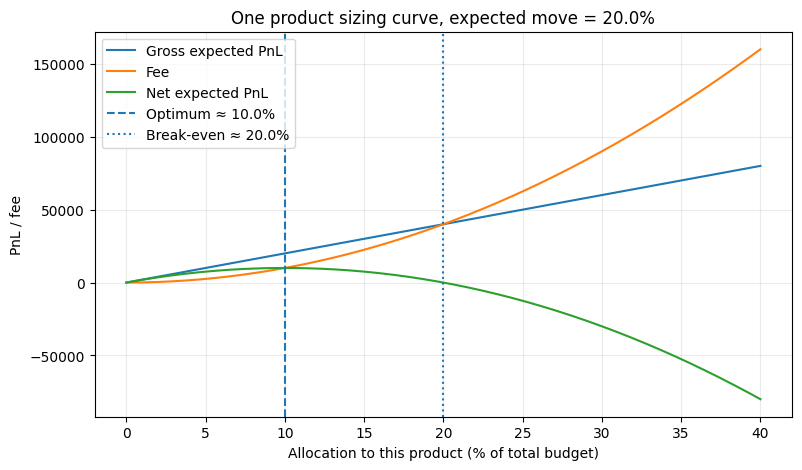

In [4]:
def plot_single_product_fee_curve(expected_return_pct=20):
    mu = expected_return_pct / 100
    ws = np.linspace(0, min(1, max(0.05, 2 * abs(mu))), 300)
    gross = BUDGET * ws * abs(mu)
    fees = BUDGET * ws**2
    net = gross - fees

    opt_w = abs(mu) / 2
    breakeven_w = abs(mu)

    plt.figure(figsize=(9, 5))
    plt.plot(100 * ws, gross, label="Gross expected PnL")
    plt.plot(100 * ws, fees, label="Fee")
    plt.plot(100 * ws, net, label="Net expected PnL")
    plt.axvline(100 * opt_w, linestyle="--", label=f"Optimum ≈ {100*opt_w:.1f}%")
    plt.axvline(100 * breakeven_w, linestyle=":", label=f"Break-even ≈ {100*breakeven_w:.1f}%")
    plt.title(f"One product sizing curve, expected move = {expected_return_pct:.1f}%")
    plt.xlabel("Allocation to this product (% of total budget)")
    plt.ylabel("PnL / fee")
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.show()

plot_single_product_fee_curve(expected_return_pct=20)


## Sensitivity to risk settings

,robust_z,risk_aversion,total_used_budget,total_used_pct,total_fee,expected_gross_pnl,expected_net_pnl
0,0.0000,0.0000,"616,500.0000",61.6500,"46,247.6250","92,495.2500","46,247.6250"
1,0.0000,1.0000,"612,950.4133",61.2950,"45,772.5235","92,018.7501","46,246.2267"
2,0.0000,3.0000,"605,996.0956",60.5996,"44,846.9199","91,082.3010","46,235.3811"
3,0.0000,5.0000,"599,226.9112",59.9227,"43,952.6637","90,167.1799","46,214.5162"
4,0.0000,10.0000,"583,056.9251",58.3057,"41,843.8190","87,967.3128","46,123.4937"
5,0.2500,0.0000,"474,250.0000",47.4250,"32,125.0625","76,237.0000","44,111.9375"
6,0.2500,1.0000,"471,786.6451",47.1787,"31,816.3260","75,862.3954","44,046.0694"
7,0.2500,3.0000,"466,942.7327",46.6943,"31,213.1970","75,125.1070","43,911.9100"
8,0.2500,5.0000,"462,205.8892",46.2206,"30,628.4872","74,403.2593","43,774.7721"
9,0.2500,10.0000,"450,807.6574",45.0808,"29,242.1380","72,662.8334","43,420.6954"


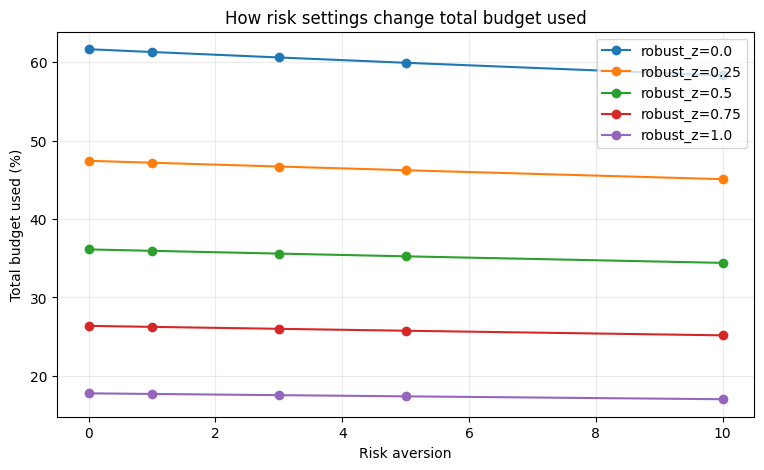

In [5]:
rows = []
for rz in [0.0, 0.25, 0.5, 0.75, 1.0]:
    for ra in [0.0, 1.0, 3.0, 5.0, 10.0]:
        a = optimise_diagonal(signals, risk_aversion=ra, robust_z=rz)
        s = portfolio_summary(a)
        rows.append({
            "robust_z": rz,
            "risk_aversion": ra,
            **s.to_dict()
        })

sensitivity = pd.DataFrame(rows)
display(sensitivity.sort_values("expected_net_pnl", ascending=False).head(20))

plt.figure(figsize=(9, 5))
for rz in sorted(sensitivity["robust_z"].unique()):
    sub = sensitivity[sensitivity["robust_z"] == rz]
    plt.plot(sub["risk_aversion"], sub["total_used_pct"], marker="o", label=f"robust_z={rz}")
plt.title("How risk settings change total budget used")
plt.xlabel("Risk aversion")
plt.ylabel("Total budget used (%)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()


## Monte Carlo stress test

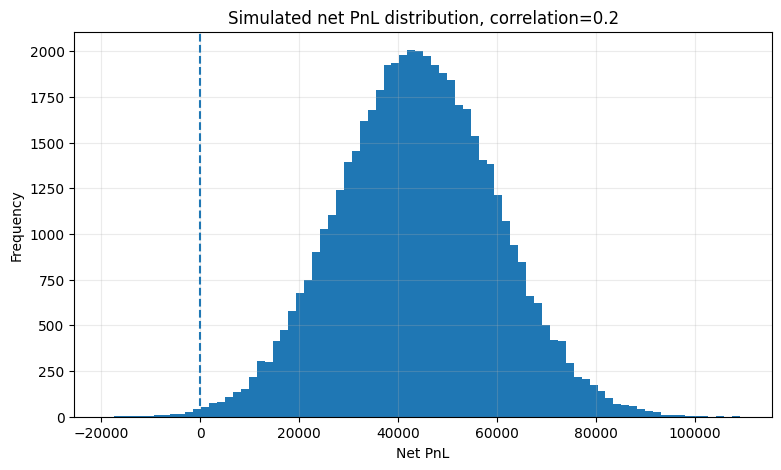

mean_net_pnl     43,965.8228
median_net_pnl   43,905.2528
p05_net_pnl      18,004.2044
p01_net_pnl       7,352.0234
prob_negative         0.0026
fixed_fee        31,213.1970
dtype: float64

In [6]:
def simulate_portfolio(df, alloc, n_sims=50_000, seed=42, correlation=0.0):
    """
    Simple Monte Carlo with equal pairwise correlation.
    Replace this with a custom covariance matrix if you have better assumptions.
    """
    rng = np.random.default_rng(seed)

    tmp = prepare_signals(df)
    tmp = tmp.set_index("product")
    a = alloc.set_index("product")
    products = a.index.tolist()

    w = a.loc[products, "allocation_pct"].to_numpy() / 100
    mu = tmp.loc[products, "mu_view"].to_numpy()
    sigma = tmp.loc[products, "sigma"].to_numpy()

    n = len(products)
    corr = np.full((n, n), correlation)
    np.fill_diagonal(corr, 1.0)
    cov = np.outer(sigma, sigma) * corr

    returns = rng.multivariate_normal(mean=mu, cov=cov, size=n_sims)
    gross = BUDGET * returns @ w
    fee = np.sum(fee_from_weight(w))
    net = gross - fee

    stats = pd.Series({
        "mean_net_pnl": net.mean(),
        "median_net_pnl": np.median(net),
        "p05_net_pnl": np.quantile(net, 0.05),
        "p01_net_pnl": np.quantile(net, 0.01),
        "prob_negative": np.mean(net < 0),
        "fixed_fee": fee,
    })

    plt.figure(figsize=(9, 5))
    plt.hist(net, bins=80)
    plt.axvline(0, linestyle="--")
    plt.title(f"Simulated net PnL distribution, correlation={correlation}")
    plt.xlabel("Net PnL")
    plt.ylabel("Frequency")
    plt.grid(True, alpha=0.25)
    plt.show()

    return stats

simulate_portfolio(signals, alloc, correlation=0.2)


## Final order table

In [7]:
orders = alloc.copy()
orders["submit_weight_pct_abs"] = orders["allocation_pct"].abs()
orders["side"] = np.where(orders["allocation_pct"] > 0, "BUY", np.where(orders["allocation_pct"] < 0, "SELL", "NO TRADE"))

orders_to_submit = orders.loc[orders["submit_weight_pct_abs"] > 0.01, [
    "product", "side", "submit_weight_pct_abs", "allocation_pct",
    "breakeven_return_pct", "expected_net_pnl"
]].sort_values("submit_weight_pct_abs", ascending=False)

display(orders_to_submit)

print("Total absolute allocation %:", orders_to_submit["submit_weight_pct_abs"].sum().round(2))
print("Total expected net PnL:", orders_to_submit["expected_net_pnl"].sum().round(0))


,product,side,submit_weight_pct_abs,allocation_pct,breakeven_return_pct,expected_net_pnl
0,SULFUR_REACTOR,BUY,9.9049,9.9049,9.9049,"11,980.0784"
6,LAVA_CAKES,SELL,9.1133,-9.1133,9.1133,"10,832.7064"
7,OBSIDIAN_CUTLERY,SELL,5.9176,-5.9176,5.9176,"5,256.2477"
1,THERMALITE_SMART_HOME_DEVICES,BUY,5.6650,5.6650,5.6650,"4,721.7841"
8,PYROFLEX_CELL,SELL,4.9261,-4.9261,4.9261,"3,730.9811"
9,ASHES_OF_THE_PHOENIX,SELL,4.8764,-4.8764,4.8764,"4,083.2966"
2,LAVA_FOUNTAIN_PEN,BUY,3.3005,3.3005,3.3005,"1,947.1281"
3,MAGMA_INK,BUY,1.9704,1.9704,1.9704,892.5235
4,SCORIA_PASTE,BUY,1.0200,1.0200,1.0200,467.1641


Total absolute allocation %: 46.69
Total expected net PnL: 43912.0


## How to use this notebook

1. Replace the product names with the exact names from the manual round UI.
2. Edit `expected_return_pct` based on your read of the articles.
3. Increase `std_pct` for noisy / pump-like stories.
4. Use `confidence` to shrink uncertain news.
5. Use `crowd_return_pct` if you think other teams' submissions will push the realised return in the same direction.
6. Tune `ROBUST_Z` and `RISK_AVERSION`.
7. Use the final `orders_to_submit` table.

Remember: because fee is quadratic, using less than 100% budget can be optimal.
